# Welcome to the RandQuantKry Tutorial Part 4

This is the forth tutorial for **RandQuantKry** on how to study parameters. <a href="tutorial.ipynb"><b>Part 1</b></a>, on how to set up a hamiltonian, an initial state and run a time evolution, along with <a href="tutorial_evolution_methods.ipynb"><b> Part 2</b></a> on how to call the different evolution methods and <a href="tutorial_benchmarking.ipynb"><b> Part 3</b></a> on how to benchmark can be found in the respectively named Jupyter Notebooks. Happy parametering :)

In [1]:
# imports
import numpy as np
import pandas as pd
from pathlib import Path
# these files can be found in src/ and are the main building blocks of this package
from randquantkry.hamiltonian import build_hamiltonian
from randquantkry.benchmark import Benchmark
from randquantkry.post_processing import plot_parameter_study
# utils/ contains all helper functions that allow for example logging
from randquantkry.utils.logging_config import configure_logging
from randquantkry.utils.reproducible_runs import load_run
from randquantkry.utils.meta_metadata_file_generator import build_run_index

In [2]:
configure_logging(console_level='INFO')

19:53:31 | INFO     | randquantkry | logging configured (console only)


<Logger randquantkry (DEBUG)>

As always we start by setting up our hamiltonian and initial state and we also set up our benchmarking object

In [3]:
n_qubits = 20
rng = np.random.default_rng(0)

terms = []
for i in range(n_qubits):
    terms.append(('X', i, float(rng.uniform(0.5, 1.5))))       # X field, every qubit
for i in range(n_qubits - 1):
    terms.append(('ZZ', i, float(rng.uniform(0.3, 0.8))))      # ZZ coupling, every neighboring pair

hamiltonian = build_hamiltonian(n_qubits, terms)
n_qubits = hamiltonian.num_qubits
initial_state = np.zeros(2**n_qubits, dtype=complex)
initial_state[128] = 1.0   


19:53:31 | INFO     | randquantkry.hamiltonian | build_hamiltonian: built | {'context': {'n_qubits': 20, 'matrix_dim': 1048576, 'n_terms': 39}}


In [4]:

time = 2.0
krylov_dim=50
num_random_vectors=2*krylov_dim+1
seed = 67

benchmark1 = Benchmark(hamiltonian, initial_state, time, krylov_dim, num_random_vectors, seed = seed)

For the parameter study we have a few different values to vary depending on what we are interested in :

* **System Size (`n_qubits_list`):** Number of qubits $n$ (determines Hilbert space dimension $2^n$).
* **Krylov Subspace Dimension (`krylov_dim_list`):** The maximum basis size $m$ constructed during iteration.
* **Sketch Ratio (`s_ratio`):** Sets the sketch dimension relative to the Krylov size via $s = \lceil \text{s\_ratio} \times m \rceil$.
* **Evolution Time (`time_list`):** Simulation time steps $t$ used to evaluate convergence and error accumulation.

#### Execution & Artifact Logging
The `parameter_study()` function executes a grid search over all parameter combinations and automatically archives every run into the <a href="../results/"><b>results/</b></a> directory. 

Each benchmark run is assigned a unique **Run ID** and stores three core artifacts:
* `metadata.json`: Full configuration, system specs, and parameter settings.
* `results.jsonl`: State fidelity, runtime, and accuracy metrics for each parameter combination.
* `run.log.jsonl`: Structured execution logs for detailed debugging and analysis.

In [5]:
rows, run_dir = benchmark1.parameter_study(
    n_qubits_list=[6, 8, 10],                                  
    krylov_dim_list=[20, 40, 60],                                  
    s_ratio_list=[2.0],    
    time_list=[0.5, 1.0, 2.0],                                        
    methods=("naive", "krylov", "randomized_krylov"),                        
    seed=67,
)

19:53:31 | INFO     | randquantkry | logging configured | {'context': {'json_path': '/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z/run.log.jsonl'}}
19:53:31 | INFO     | randquantkry.benchmark | run_parameter_study: starting | {'context': {'run_dir': '/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z', 'n_qubits_list': [6, 8, 10], 'krylov_dim_list': [20, 40, 60], 's_ratio_list': [2.0], 'time_list': [0.5, 1.0, 2.0], 'methods': ['naive', 'krylov', 'randomized_krylov'], 'total_base_points': 27}}
19:53:31 | INFO     | randquantkry.hamiltonian | reconstruct_hamiltonian: reconstructed | {'context': {'n_qubits': 6, 'n_original_terms': 39, 'gate_types': ['X', 'ZZ']}}
19:53:31 | INFO     | randquantkry.hamiltonian | build_hamiltonian: built | {'context': {'n_qubits': 6, 'matrix_dim': 64, 'n_terms': 11}}
19:53:31 | WARNING  | randquantkry.benchmark | num_random_vectors exceeds N=2**n_qubits;

19:53:31 | INFO     | randquantkry.evolution | time_evolve_naive: complete | {'context': {'evolved_state_norm': 1.000000000000001}}
19:53:31 | INFO     | randquantkry.evolution | time_evolve_krylov: starting | {'context': {'n_qubits': 6, 'matrix_dim': 64, 'time': 0.5, 'krylov_dim_requested': 20}}
19:53:31 | INFO     | randquantkry.evolution | time_evolve_krylov: basis built | {'context': {'krylov_dim_requested': 20, 'k_reached': 20, 'Tri_shape': (20, 20)}}
19:53:31 | INFO     | randquantkry.evolution | time_evolve_krylov: complete | {'context': {'evolved_state_norm': 0.9999999999999999}}
19:53:31 | INFO     | randquantkry.evolution | time_evolve_randomized_krylov: starting | {'context': {'n_qubits': 6, 'matrix_dim': 64, 'time': 0.5, 'krylov_dim_requested': 20, 'num_random_vectors': 40}}
19:53:31 | INFO     | randquantkry.evolution | time_evolve_randomized_krylov: complete | {'context': {'evolved_state_norm': 1.0}}
19:53:31 | INFO     | randquantkry.evolution | time_evolve_krylov: start

As mentioned earlier the results are written out into a directory with a unique run ID. Using the *build_run_index* function that ID can be mapped to the parameters used:

In [6]:
# from the notebook, go up to repo root explicitly
repo_root = Path.cwd().parent  # if notebook is one level inside repo root, e.g. scripts/
results_dir = repo_root / "results" 

In [7]:
build_run_index(results_dir=repo_root / "results")[["run_id", "qubits", "krylov_dims", "times", "methods", "s_ratios"]]

Successfully cataloged 14 runs -> /mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_index.csv and /mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/RUN_INDEX.md


,run_id,qubits,krylov_dims,times,methods,s_ratios
0,run_20260723T081242Z,"6, 8, 10, 14, 18","20, 40, 60, 80","1, 5, 10, 20","naive, krylov, randomized_krylov",2.0
1,run_20260723T165748Z,6,,1.0,"naive, krylov, randomized_krylov",
2,run_20260723T165908Z,"6, 8, 10, 12, 14, 16, 18",,1.0,"naive, krylov, randomized_krylov",
3,run_20260723T170433Z,"6, 8, 10, 14, 18","20, 40, 60, 80","1, 5, 10, 20","naive, krylov, randomized_krylov",2.0
4,run_20260723T171003Z,"6, 8, 10, 14, 18","20, 40, 60, 80","0.5, 1.0, 2.0","naive, krylov, randomized_krylov",2.0
5,run_20260723T172415Z,"6, 8, 10, 12, 14, 16, 18",,1.0,"naive, krylov, randomized_krylov",
6,run_20260723T173052Z,6,,1.0,"naive, krylov, randomized_krylov",
7,run_20260723T173137Z,6,,1.0,"naive, krylov, randomized_krylov",
8,run_20260723T173210Z,"6, 8, 10, 14, 16, 18",,1.0,"naive, krylov, randomized_krylov",
9,run_20260723T173615Z,"6, 8, 10","20, 40, 60","0.5, 1.0, 2.0","naive, krylov, randomized_krylov",2.0


To plot the benchmark results, you can either pass the summary DataFrame generated above or load the detailed `results.jsonl` file directly from a specific run directory:

In [8]:
output_dir = results_dir / "run_20260723T081242Z" # <-- your unique run ID here
# or in this case we can simply use the run_dir that was returned above
output_dir = run_dir

In [9]:
df, meta = load_run(output_dir)

The plotting functionality is defined in <a href="../src/post_processing.py"><b>post_processing.py</b></a>. It allows you to select variables for the **X** and **Y** axes while holding remaining parameters fixed.

Supported variables for axis selection and filtering include:
* `"n_qubits"`: System size (number of qubits)
* `"krylov_dim"`: Dimension of the Krylov subspace ($m$)
* `"time"`: Evolution time ($t$)
* `"s_ratio"`: Sketch ratio ($s = \lceil \text{s\_ratio} \times m \rceil$)
* `"rel_error"`: Relative state error compared to exact evolution

19:54:29 | INFO     | randquantkry.post_processing | Plot saved | {'context': {'target_path': PosixPath('/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z/plots/rel_error_vs_n_qubits_krylov_dim20_time0.5.png')}}


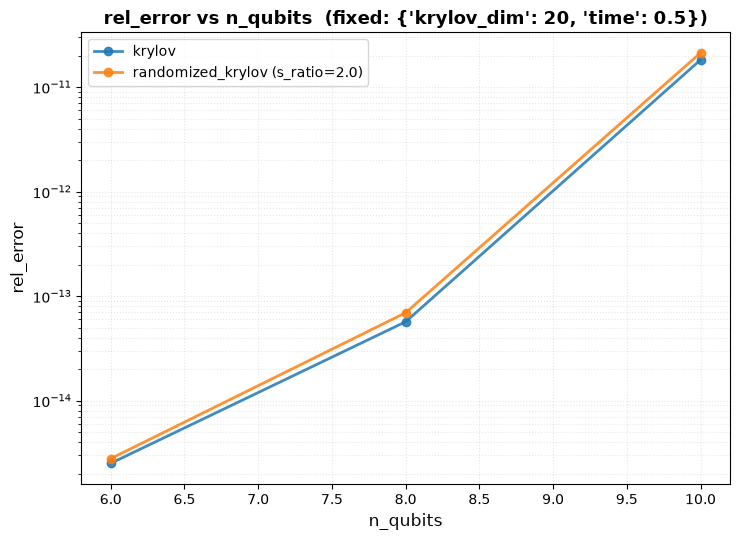

19:54:30 | INFO     | randquantkry.post_processing | Plot saved | {'context': {'target_path': PosixPath('/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z/plots/rel_error_vs_n_qubits_krylov_dim20_time1.0.png')}}


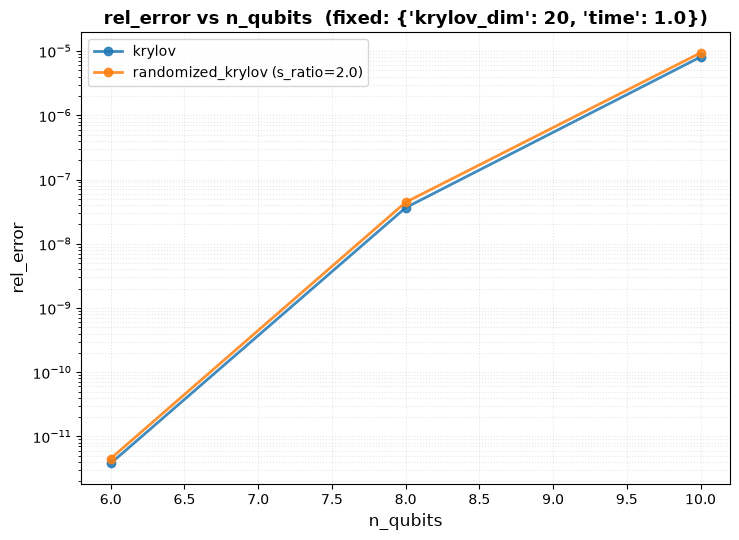

19:54:32 | INFO     | randquantkry.post_processing | Plot saved | {'context': {'target_path': PosixPath('/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z/plots/rel_error_vs_n_qubits_krylov_dim20_time2.0.png')}}


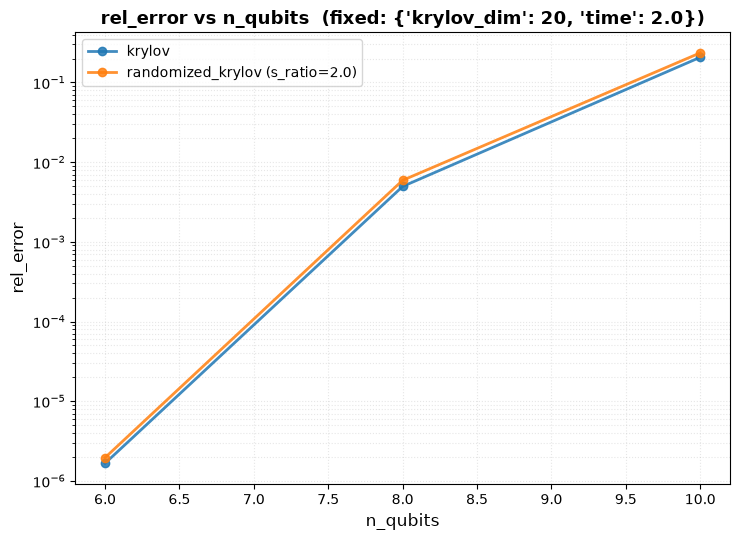

19:54:33 | INFO     | randquantkry.post_processing | Plot saved | {'context': {'target_path': PosixPath('/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z/plots/rel_error_vs_n_qubits_krylov_dim40_time0.5.png')}}


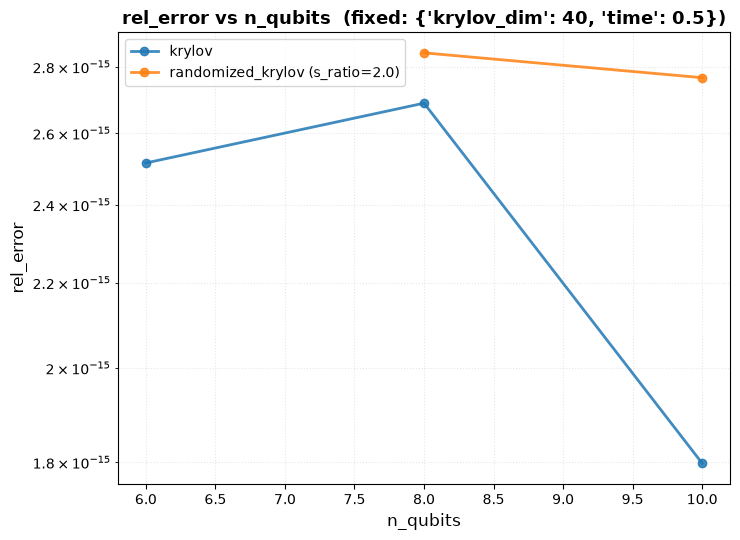

19:54:33 | INFO     | randquantkry.post_processing | Plot saved | {'context': {'target_path': PosixPath('/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z/plots/rel_error_vs_n_qubits_krylov_dim40_time1.0.png')}}


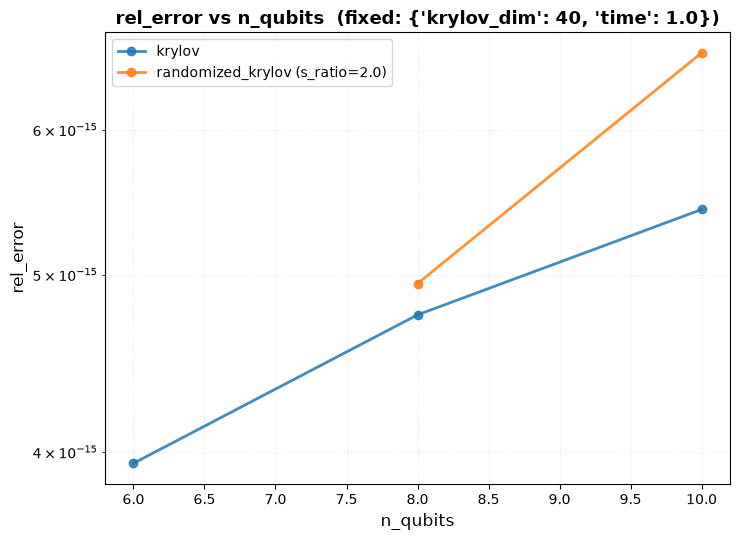

19:54:34 | INFO     | randquantkry.post_processing | Plot saved | {'context': {'target_path': PosixPath('/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z/plots/rel_error_vs_n_qubits_krylov_dim40_time2.0.png')}}


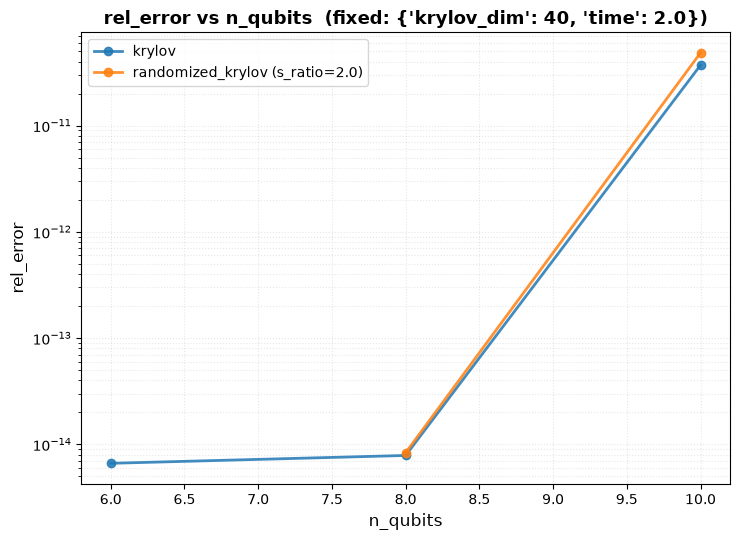

19:54:34 | INFO     | randquantkry.post_processing | Plot saved | {'context': {'target_path': PosixPath('/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z/plots/rel_error_vs_n_qubits_krylov_dim60_time0.5.png')}}


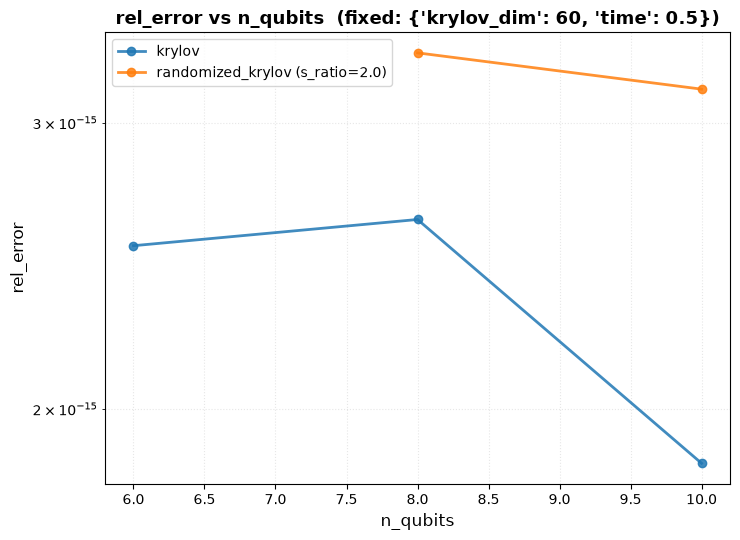

19:54:35 | INFO     | randquantkry.post_processing | Plot saved | {'context': {'target_path': PosixPath('/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z/plots/rel_error_vs_n_qubits_krylov_dim60_time1.0.png')}}


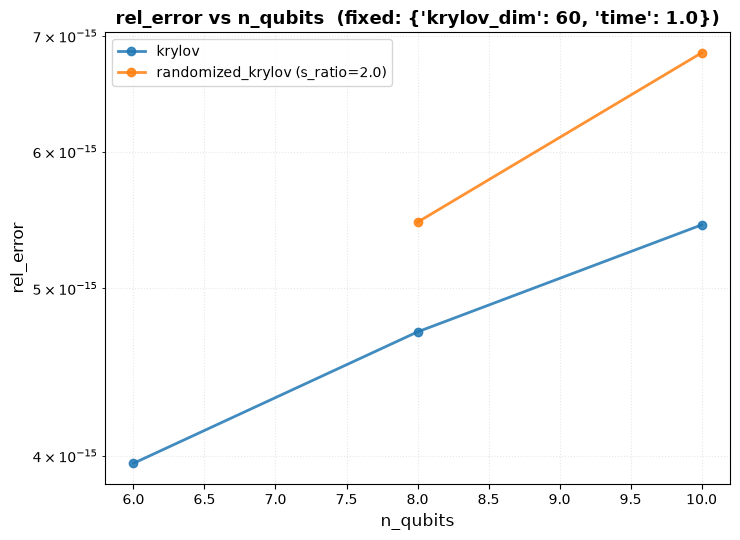

19:54:36 | INFO     | randquantkry.post_processing | Plot saved | {'context': {'target_path': PosixPath('/mnt/c/Users/Feli/OneDrive/Documents/Mastersemester_II/SCE/randquantkry/results/run_20260723T175331Z/plots/rel_error_vs_n_qubits_krylov_dim60_time2.0.png')}}


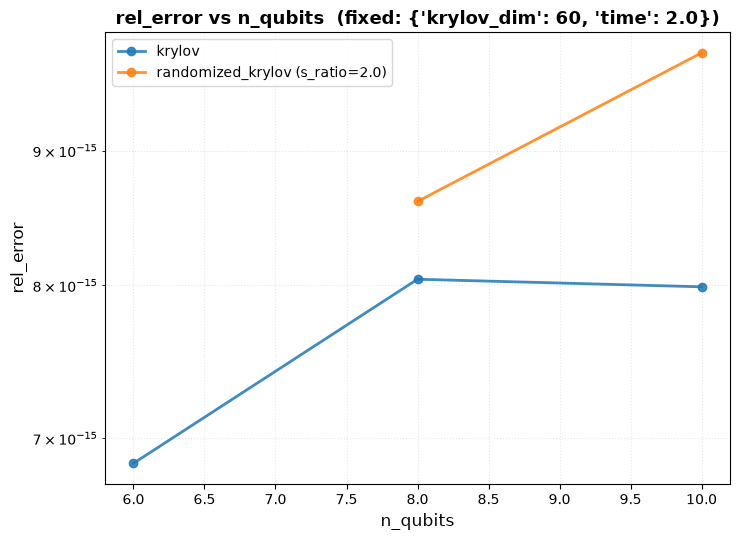

In [10]:
for kdim in [20, 40, 60]:
    for t in [0.5, 1.0, 2.0]:
        plot_parameter_study(df, x="n_qubits", y="rel_error", fixed={"krylov_dim":kdim, "time": t}, run_dir=output_dir)

<div class="alert alert-block alert-info">
<b>For now: </b> 

The plots are just simple matplotlib plots but there are better visualizations in the works.

</div>